# Non-Maturity Deposit Behaviour Modelling

Checking and savings accounts can be withdrawn any day, yet most of the money stays for years and earns a rate that barely follows the market. That makes them a bank's cheapest and most stable funding, until it is not: in 2022–2023 about a trillion dollars left U.S. bank deposits for money-market funds. This notebook estimates the two behaviours that decide how much risk sits in these deposits and turns them into the inputs an ALM model needs.

**What it does.** It models the two behaviours that decide how much interest-rate and liquidity risk sits in non-maturity deposits (NMDs):

- how much of a policy-rate move banks pass on to depositors (the **deposit beta**, which differs between hikes and cuts);
- how deposit **volumes** react to the gap between market and deposit rates.

It then turns them into the behavioural inputs an IRRBB or ALM model needs: the core share, the decay curve and the weighted average life.

**Data.** FDIC national deposit rates for savings, money-market and 12-month CDs, spliced across the 2021 methodology change, the effective fed funds rate, H.8 deposits, large and small time deposits, and retail money-market fund balances (all FRED).

**Methods.** Cycle betas and an asymmetric error-correction model (OLS), and a generalised additive model of deposit growth (statsmodels GAM with B-splines) against a linear benchmark.

A discrete-time proportional-hazards model (complementary log-log GLM, the monthly equivalent of Cox) with a time-varying rate gap runs on a synthetic account panel driven by the real rate path. An LSTM, ARIMA and a GAM-type regression are compared for forecasting deposit growth.

**Key output.** Betas by product and cycle, the nonlinear volume response to the rate gap, deposit decay curves and average life under three rate scenarios, and out-of-sample forecast accuracy.

## 1. Why NMDs are the hardest line in an ALM model

Checking, savings and money-market accounts have no contractual maturity: the customer can leave any day. In practice, though, most balances stay for years and their rate barely moves with the market. That makes them the cheapest and most stable funding a bank has. Two numbers decide how an ALM or IRRBB model treats them:

1. **The deposit beta:** the share of a policy-rate change passed on to depositors. A low beta makes deposits behave like long fixed-rate funding; a high beta makes them floating.
2. **Volume behaviour:** how much money leaves when market rates are well above deposit rates. 2022–2023 showed it clearly: as the fed funds rate rose 5 points and deposit rates lagged, about $1tn moved from bank deposits to money-market funds.

Both are behavioural assumptions, which is why supervisors (BCBS 368, the EBA IRRBB guidelines) ask banks to estimate and validate them. For a counterparty analyst, the same numbers show how exposed a bank's margin and funding are to the rate cycle.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import statsmodels.api as sm
from statsmodels.gam.api import BSplines, GLMGam
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

START = "1985-01-01"
# out-of-sample period for the volume forecasts
TEST_START = "2017-01-01"
# synthetic account panel for the survival model
N_ACCOUNTS = 12_000
SEED = 19
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"statsmodels {sm.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

statsmodels 0.15.0 · torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


PRODUCT_COLORS = {
    "Savings": PALETTE[0],
    "Money market": PALETTE[2],
    "12-month CD": PALETTE[1],
}

## 3. Data

FDIC national rates changed methodology in April 2021, so each product is spliced: the pre-2021 non-jumbo series (2009–2021) followed by the new national rate. Non-maturity deposits are H.8 total deposits minus large time deposits and minus small-denomination time deposits, a consistent definition since the 1980s.

In [3]:
SERIES = {
    "FEDFUNDS": "fed funds",
    "SAVNRNJ": "savings old",
    "SNDR": "savings new",
    "MMNRNJ": "mm old",
    "MMNDR": "mm new",
    "CD12NRNJ": "cd old",
    "NDR12MCD": "cd new",
    "DPSACBW027SBOG": "deposits",
    "LTDACBW027SBOG": "large time",
    "STDSL": "small time",
    "RMFSL": "retail MMF",
}


def fetch():
    out = {}
    for sid, name in SERIES.items():
        s = fred.get_series(sid, observation_start=START).dropna()
        s.index = pd.to_datetime(s.index)
        out[name] = s.resample("MS").mean()
    return pd.DataFrame(out).rename_axis("date").reset_index()


raw = cached("fred_nmd", fetch).set_index("date")
m = pd.DataFrame(index=raw.index)
m["fed funds"] = raw["fed funds"]
for prod, (old, new) in {
    "Savings": ("savings old", "savings new"),
    "Money market": ("mm old", "mm new"),
    "12-month CD": ("cd old", "cd new"),
}.items():
    m[prod] = raw[new].combine_first(raw[old])
m["NMD $bn"] = raw["deposits"] - raw["large time"] - raw["small time"]
m["retail MMF $bn"] = raw["retail MMF"]
m = m[m.index < pd.Timestamp.today().normalize().replace(day=1)]
rates = m.loc[
    "2009-06":, ["fed funds", "Savings", "Money market", "12-month CD"]
].dropna()
print(
    f"Deposit rates {rates.index.min():%Y-%m} → {rates.index.max():%Y-%m} ·"
    f" NMD {m['NMD $bn'].dropna().index.min():%Y-%m} →"
    f" {m['NMD $bn'].dropna().index.max():%Y-%m} (latest"
    f" ${m['NMD $bn'].dropna().iloc[-1] / 1e3:,.1f}tn)"
)
rates.iloc[[0, -1]].round(2)

Deposit rates 2009-06 → 2026-09 · NMD 1985-01 → 2026-08 (latest $15.5tn)


,fed funds,Savings,Money market,12-month CD
date,,,,
2009-06-01,0.21,0.21,0.44,1.22
2026-09-01,3.75,0.37,0.63,1.73


## 4. Deposit betas

**Cycle betas** are the simplest and most quoted measure: the change in the deposit rate over a cycle divided by the change in fed funds. Three complete or ongoing cycles are in the data: the 2015–2019 hikes, the 2022–2023 hikes, and the cuts since September 2024.

The **asymmetric error-correction model** separates the speed of adjustment from the long-run level:

$$
\Delta d_t = a + b^{+}\,\Delta f^{+}_t + b^{-}\,\Delta f^{-}_t + \gamma\,(d_{t-1} - \theta f_{t-1}) + \varepsilon_t ,
$$

where $\theta$ is the long-run beta from the levels regression, $b^{\pm}$ the immediate pass-through of rises and falls, and $\gamma<0$ the speed at which the gap closes.

In [4]:
CYCLES = {
    "Hikes 2015–2019": ("2015-11", "2019-07"),
    "Hikes 2022–2023": ("2022-02", "2023-08"),
    "Cuts 2024–": ("2024-08", rates.index[-1].strftime("%Y-%m")),
}
PRODUCTS = ["Savings", "Money market", "12-month CD"]


def at_start(dt, col):
    # first month on or after the cycle start
    return rates.loc[dt:, col].iloc[0]


def at_end(dt, col):
    # last month up to the cycle end
    return rates.loc[:dt, col].iloc[-1]


cycle_beta = pd.DataFrame({
    c: {
        p: (at_end(b, p) - at_start(a, p)) / (
            at_end(b, "fed funds") - at_start(a, "fed funds")
        )
        for p in PRODUCTS
    }
    for c, (a, b) in CYCLES.items()
}).T

ecm_rows = {}
for p in PRODUCTS:
    d, f = rates[p], rates["fed funds"]
    theta = sm.OLS(d, sm.add_constant(f)).fit().params["fed funds"]
    df = pd.DataFrame({
        "dd": d.diff(),
        "up": f.diff().clip(lower=0),
        "down": f.diff().clip(upper=0),
        "gap": (d - theta * f).shift(1),
    }).dropna()
    fit = sm.OLS(df["dd"], sm.add_constant(df[["up", "down", "gap"]])).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6}
    )
    ecm_rows[p] = {
        "long-run beta θ": theta,
        "b+ (rises)": fit.params["up"],
        "b− (falls)": fit.params["down"],
        "γ (speed)": fit.params["gap"],
        "half-life (months)": np.log(0.5) / np.log(1 + fit.params["gap"]),
        "p(b+ = b−)": float(fit.t_test("up - down = 0").pvalue),
        "R²": fit.rsquared,
    }
ecm = pd.DataFrame(ecm_rows).T
display(cycle_beta.round(2))
ecm.round(3)

,Savings,Money market,12-month CD
Hikes 2015–2019,0.02,0.04,0.17
Hikes 2022–2023,0.07,0.10,0.31
Cuts 2024–,0.06,0.01,0.08


,long-run beta θ,b+ (rises),b− (falls),γ (speed),half-life (months),p(b+ = b−),R²
Savings,0.07,0.05,0.01,-0.02,32.20,0.00,0.41
Money market,0.10,0.06,0.03,-0.04,17.43,0.16,0.35
12-month CD,0.29,0.20,0.10,-0.05,14.07,0.02,0.51


## 5. Volumes: do deposits leave when the rate gap widens?

Monthly NMD growth (log, annualised) is modelled against the **opportunity cost**: fed funds minus the savings rate (the money-market rate a customer could get elsewhere, minus what the bank pays). A linear regression assumes every point of gap costs the same outflow. A **GAM** with a B-spline in the gap lets the response bend.

Both include the change in fed funds and lagged growth. Fitted on 2009–2026, the period with deposit-rate data.

In [5]:
v = (
    pd.DataFrame({
        "growth": np.log(m["NMD $bn"]).diff() * 1200,
        "gap": m["fed funds"] - m["Savings"],
        "dff": m["fed funds"].diff(),
        "mmf growth": np.log(m["retail MMF $bn"]).diff() * 1200,
    })
    .loc["2009-07":]
    .dropna()
)
v["growth lag"] = v["growth"].shift(1)
v = v.dropna()
# stimulus deposit surge: excluded from the fit
covid = (v.index >= "2020-03-01") & (v.index <= "2021-06-01")
vf = v[~covid]
lin = sm.OLS(
    vf["growth"], sm.add_constant(vf[["gap", "dff", "growth lag"]])
).fit()
bs = BSplines(vf[["gap"]], df=[6], degree=[3])
gam = GLMGam(
    vf["growth"],
    exog=sm.add_constant(vf[["dff", "growth lag"]]),
    smoother=bs,
    alpha=[1.0],
).fit()
grid = np.linspace(vf["gap"].min(), vf["gap"].max(), 60)
# Response to the gap with the other inputs held at typical values (Δff = 0,
# lagged growth at its mean), relative to a 25 bp gap
ex = pd.DataFrame(
    {"const": 1.0, "dff": 0.0, "growth lag": vf["growth lag"].mean()},
    index=range(len(grid)),
)
gam_pred = np.asarray(gam.predict(exog=ex, exog_smooth=grid[:, None]))
lin_pred = np.asarray(
    lin.predict(
        pd.DataFrame({
            "const": 1.0,
            "gap": grid,
            "dff": 0.0,
            "growth lag": vf["growth lag"].mean(),
        })
    )
)
gam_curve = gam_pred - np.interp(0.25, grid, gam_pred)
lin_curve = lin_pred - np.interp(0.25, grid, lin_pred)
print(
    f"Linear: {lin.params['gap']:.2f} pts of annualised growth per point of"
    f" gap (R² {lin.rsquared:.2f}) · GAM deviance explained"
    f" {1 - gam.deviance / gam.null_deviance:.2f} · AIC linear"
    f" {lin.aic:.0f} vs GAM {gam.aic:.0f}"
)
corr_mmf = v["gap"].corr(v["mmf growth"])
print(f"Correlation of the gap with money-fund growth: {corr_mmf:.2f}")
pd.DataFrame({
    "gap (pts)": grid[::10],
    "GAM effect": gam_curve[::10],
    "linear effect": lin_curve[::10],
}).round(2)

Linear: -1.34 pts of annualised growth per point of gap (R² 0.60) · GAM deviance explained 0.60 · AIC linear 1191 vs GAM 1191
Correlation of the gap with money-fund growth: 0.53


,gap (pts),GAM effect,linear effect
0,-0.10,1.57,0.47
1,0.75,-1.37,-0.67
2,1.60,-2.22,-1.80
3,2.44,-2.75,-2.94
4,3.29,-3.59,-4.07
5,4.14,-4.72,-5.20


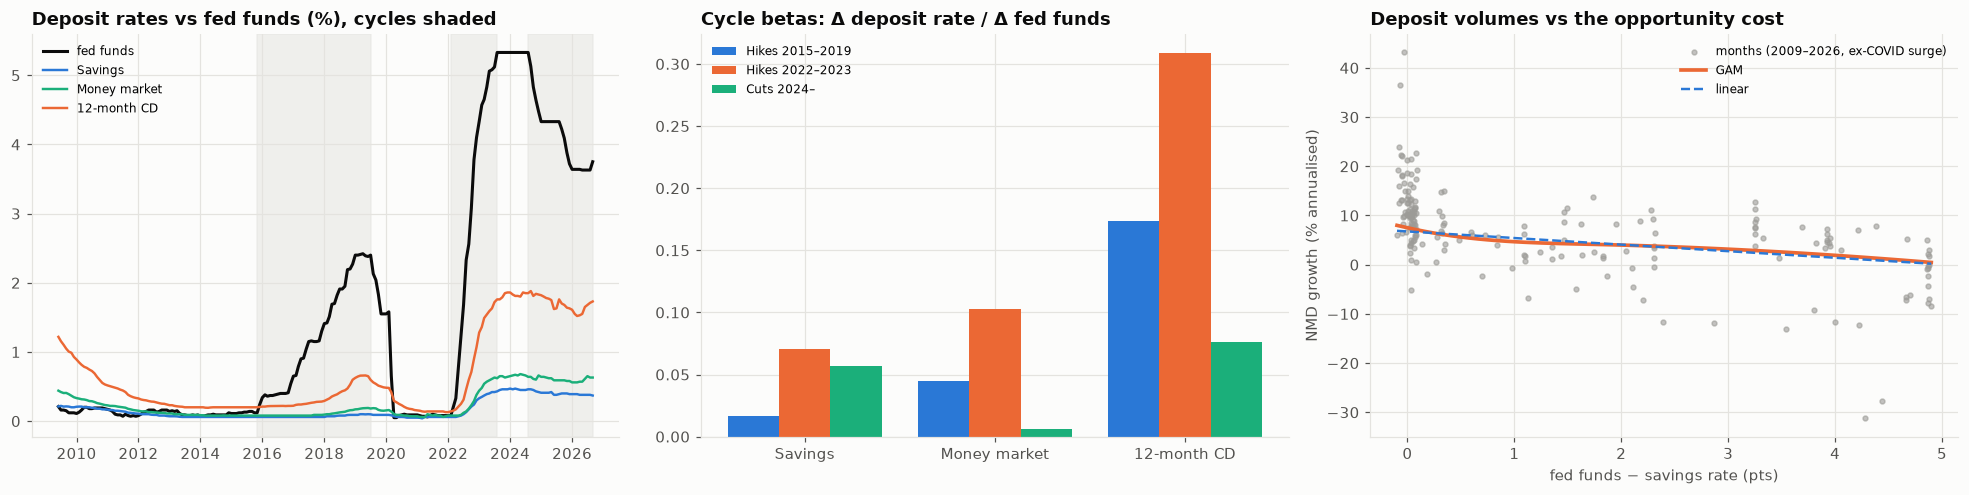

In [6]:
# --- Chart 1: betas and the volume response
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
ax = axes[0]
ax.plot(rates.index, rates["fed funds"], color=INK, lw=2, label="fed funds")
for p, c in PRODUCT_COLORS.items():
    ax.plot(rates.index, rates[p], color=c, lw=1.6, label=p)
for c, (a, b) in CYCLES.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#e4e3df", alpha=0.5)
ax.set_title("Deposit rates vs fed funds (%), cycles shaded")
ax.legend(fontsize=8)
ax = axes[1]
xb = np.arange(len(PRODUCTS))
for k, c in enumerate(cycle_beta.index):
    ax.bar(
        xb + (k - 1) * 0.27,
        cycle_beta.loc[c],
        0.27,
        label=c,
        color=[PALETTE[0], PALETTE[1], PALETTE[2]][k],
    )
ax.set_xticks(xb, PRODUCTS)
ax.set_title("Cycle betas: Δ deposit rate / Δ fed funds")
ax.legend(fontsize=8)
ax = axes[2]
ax.scatter(
    vf["gap"],
    vf["growth"],
    s=10,
    color="#9c9b97",
    alpha=0.6,
    label="months (2009–2026, ex-COVID surge)",
)
base = vf["growth"].mean()
ax.plot(grid, base + gam_curve, color=PALETTE[1], lw=2.4, label="GAM")
ax.plot(
    grid, base + lin_curve, color=PALETTE[0], lw=1.6, ls="--", label="linear"
)
ax.set_xlabel("fed funds − savings rate (pts)")
ax.set_ylabel("NMD growth (% annualised)")
ax.set_title("Deposit volumes vs the opportunity cost")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_betas_and_volume_response")
plt.show()

## 6. Decay: a survival model of account balances

Aggregate data cannot say how long a *given* dollar stays. Banks estimate this from account-level data, which is confidential. To show the method end to end, the notebook simulates a panel of 12,000 accounts opened between 2010 and 2024. Each month an account closes (or moves its balance) with a hazard that depends on tenure and on the **real** monthly rate gap from Section 5, with known coefficients.

A **discrete-time proportional-hazards model** is then fitted to the panel to show that it recovers those coefficients. With monthly data, a complementary log-log regression on account-months is the discrete counterpart of a Cox model with a time-varying covariate, and it also estimates the baseline hazard, including the extra churn of new accounts, which the projections need.

From the fitted model, decay curves and the weighted average life of the deposit book are computed under three rate scenarios for the next ten years.

The coefficients are illustrative. The value of this section is the pipeline a bank would run on its own account data, and the check that the estimator recovers what generated the data.

In [7]:
rng = np.random.default_rng(SEED)
gap_m = (m["fed funds"] - m["Savings"]).loc["2010-01":].dropna()
months_idx = gap_m.index
# Illustrative coefficients, chosen so that decay is in the range banks report
# for core NMD (weighted average life of 4–7 years)
TRUE = {"gap": 0.15, "rate_sensitive": 0.7, "gap_x_sensitive": 0.15}
# monthly baseline hazard (≈ 7% a year)
BASE_H = 0.006
rows = []
for i in range(N_ACCOUNTS):
    start = rng.integers(0, len(months_idx) - 24)
    # 30% rate-sensitive (online, high-balance) accounts
    sens = int(rng.random() < 0.3)
    t = 0
    for k in range(start, len(months_idx)):
        g = gap_m.iloc[k]
        # new accounts churn more
        tenure_mult = 1.6 if t < 12 else 1.0
        h = (
            BASE_H
            * tenure_mult
            * np.exp(
                TRUE["gap"] * g
                + TRUE["rate_sensitive"] * sens
                + TRUE["gap_x_sensitive"] * g * sens
            )
        )
        event = rng.random() < min(h, 0.9)
        rows.append((i, t, t + 1, g, sens, g * sens, int(t < 12), int(event)))
        t += 1
        if event:
            break
panel = pd.DataFrame(
    rows,
    columns=[
        "id",
        "start",
        "stop",
        "gap",
        "rate_sensitive",
        "gap_x_sensitive",
        "new_account",
        "event",
    ],
)
Xh = sm.add_constant(
    panel[["gap", "rate_sensitive", "gap_x_sensitive", "new_account"]]
)
dth = sm.GLM(
    panel["event"],
    Xh,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
).fit()
cox = pd.DataFrame({"coef": dth.params, "se(coef)": dth.bse, "p": dth.pvalues})
cox["true"] = pd.Series(
    {"const": np.log(BASE_H), **TRUE, "new_account": np.log(1.6)}
)
print(
    f"{len(panel):,} account-months · {panel['event'].sum():,} closures ·"
    f" {N_ACCOUNTS:,} accounts"
)
cox.round(3)

729,978 account-months · 8,592 closures · 12,000 accounts


,coef,se(coef),p,true
const,-5.12,0.02,0.00,-5.12
gap,0.16,0.01,0.00,0.15
rate_sensitive,0.74,0.03,0.00,0.70
gap_x_sensitive,0.14,0.01,0.00,0.15
new_account,0.48,0.03,0.00,0.47


In [8]:
def decay_curve(gap_path, sens_share=0.3, months=120):
    """
    Expected surviving balance share of a new book, mixing sensitive and stable
    accounts.
    """
    # fitted, including the baseline hazard and the new-account effect
    b = dth.params
    for sens, w in [(1, sens_share), (0, 1 - sens_share)]:
        s, curve = 1.0, [1.0]
        for t in range(months):
            g = gap_path[min(t, len(gap_path) - 1)]
            h = np.exp(
                b["const"]
                + b["new_account"] * (t < 12)
                + b["gap"] * g
                + b["rate_sensitive"] * sens
                + b["gap_x_sensitive"] * g * sens
            )
            s *= 1 - min(h, 0.9)
            curve.append(s)
        if sens == 1:
            sens_curve = np.array(curve)
        else:
            stable_curve = np.array(curve)
    return sens_share * sens_curve + (1 - sens_share) * stable_curve


current_gap = float(gap_m.iloc[-1])
SCENARIOS = {
    f"Gap stays at today's {current_gap:.1f} pts": np.full(120, current_gap),
    "Gap closes to 0.5 pts (cuts pass through)": (
        np.linspace(current_gap, 0.5, 24).tolist() + [0.5] * 96
    ),
    "Gap widens to 5 pts (2023-style)": (
        np.linspace(current_gap, 5.0, 12).tolist() + [5.0] * 108
    ),
}
decay = {k: decay_curve(np.array(p)) for k, p in SCENARIOS.items()}
# area under the survival curve, years (10y cap)
wal = {k: (c[:-1].sum() + c[-1] * 0) / 12 for k, c in decay.items()}
# share still there after 5 years
core = {k: c[60] for k, c in decay.items()}
behav = pd.DataFrame({
    "weighted average life (yrs, 10y cap)": wal,
    "core share after 5y": core,
    "share after 1y": {k: c[12] for k, c in decay.items()},
})
behav.round(3)

,"weighted average life (yrs, 10y cap)",core share after 5y,share after 1y
Gap stays at today's 3.4 pts,4.39,0.38,0.73
Gap closes to 0.5 pts (cuts pass through),5.41,0.51,0.76
Gap widens to 5 pts (2023-style),3.75,0.31,0.68


## 7. Forecasting deposit growth: LSTM vs ARIMA vs regression

Can deposit flows be forecast a month ahead from rates? Three models, trained on 1986–2016 and tested on 2017–2026 (which includes the 2020 stimulus surge and the 2022–2023 outflows):

- **ARIMA(2,0,1)** on monthly NMD growth;
- **Regression**: lagged growth, last month's Δfed funds and the fed funds level (deposit rates only start in 2009, so the gap cannot be used over the full history);
- **LSTM**: a one-layer network reading the last 12 months of growth, Δfed funds and fed funds.

Each forecast is one month ahead, refitted every January on all data to date (expanding window).

In [9]:
fz = (
    pd.DataFrame({
        "growth": np.log(m["NMD $bn"]).diff() * 1200,
        "ff": m["fed funds"],
        "dff": m["fed funds"].diff(),
    })
    .loc["1986-01":]
    .dropna()
)
fz.index.freq = "MS"
test_idx = fz.index[fz.index >= TEST_START]
LOOK = 12


class DepLSTM(torch.nn.Module):
    def __init__(self, h=32):
        super().__init__()
        self.lstm = torch.nn.LSTM(3, h, batch_first=True)
        self.head = torch.nn.Linear(h, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)


def windows(frame, mu, sd):
    Z = ((frame - mu) / sd).to_numpy(dtype=np.float32)
    X = np.stack([Z[i - LOOK : i] for i in range(LOOK, len(Z))])
    y = Z[LOOK:, 0]
    return torch.tensor(X), torch.tensor(y)


preds = {
    k: pd.Series(np.nan, index=test_idx)
    for k in ["ARIMA", "Regression", "LSTM", "Random walk (last month)"]
}
t0 = time.perf_counter()
for yr in sorted(set(test_idx.year)):
    train = fz[fz.index < f"{yr}-01-01"]
    block = test_idx[test_idx.year == yr]
    mu, sd = train.mean(), train.std()
    # ARIMA: one-step forecasts through the year with fixed parameters
    ar = ARIMA(train["growth"], order=(2, 0, 1)).fit()
    ar_full = ar.apply(fz.loc[: block[-1], "growth"])
    preds["ARIMA"].loc[block] = ar_full.predict(
        start=block[0], end=block[-1]
    ).to_numpy()
    # Regression
    X = pd.DataFrame({
        "lag": fz["growth"].shift(1),
        "dff": fz["dff"].shift(1),
        "ff": fz["ff"].shift(1),
    })
    reg = sm.OLS(
        train["growth"].iloc[1:], sm.add_constant(X.loc[train.index].iloc[1:])
    ).fit()
    preds["Regression"].loc[block] = reg.predict(
        sm.add_constant(X.loc[block], has_constant="add")
    ).to_numpy()
    preds["Random walk (last month)"].loc[block] = (
        fz["growth"].shift(1).loc[block].to_numpy()
    )
    # LSTM (inputs: growth, Δff, ff up to the previous month; Δff of the
    # forecast month is not used)
    feats = fz[["growth", "dff", "ff"]]
    Xtr, ytr = windows(
        feats.loc[train.index],
        mu[["growth", "dff", "ff"]],
        sd[["growth", "dff", "ff"]],
    )
    torch.manual_seed(SEED)
    net = DepLSTM()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=1e-4)
    for ep in range(150):
        loss = torch.mean((net(Xtr) - ytr) ** 2)
        opt.zero_grad()
        loss.backward()
        opt.step()
    full = feats.loc[: block[-1]]
    Z = (
        (full - mu[["growth", "dff", "ff"]]) / sd[["growth", "dff", "ff"]]
    ).to_numpy(dtype=np.float32)
    pos = [full.index.get_loc(d) for d in block]
    Xte = torch.tensor(np.stack([Z[p - LOOK : p] for p in pos]))
    with torch.no_grad():
        preds["LSTM"].loc[block] = (
            net(Xte).numpy() * sd["growth"] + mu["growth"]
        )
print(
    f"Expanding-window forecasts {test_idx[0]:%Y-%m} → {test_idx[-1]:%Y-%m} in"
    f" {time.perf_counter() - t0:.0f}s"
)
actual = fz.loc[test_idx, "growth"]
ex_covid = ~((test_idx >= "2020-03-01") & (test_idx <= "2021-06-01"))
fc = pd.DataFrame({
    k: {
        "RMSE (all)": np.sqrt(((p - actual) ** 2).mean()),
        "RMSE (ex 2020–21 surge)": np.sqrt(
            ((p - actual)[ex_covid] ** 2).mean()
        ),
        "RMSE 2022–23 outflow": np.sqrt(
            ((p - actual).loc["2022-03":"2023-12"] ** 2).mean()
        ),
        "direction hit %": (np.sign(p) == np.sign(actual)).mean() * 100,
    }
    for k, p in preds.items()
}).T
fc.round(2)

Expanding-window forecasts 2017-01 → 2026-08 in 10s


,RMSE (all),RMSE (ex 2020–21 surge),RMSE 2022–23 outflow,direction hit %
ARIMA,10.16,4.84,8.20,91.38
Regression,7.93,5.24,7.64,90.52
LSTM,11.81,5.48,8.18,90.52
Random walk (last month),9.25,4.67,6.54,89.66


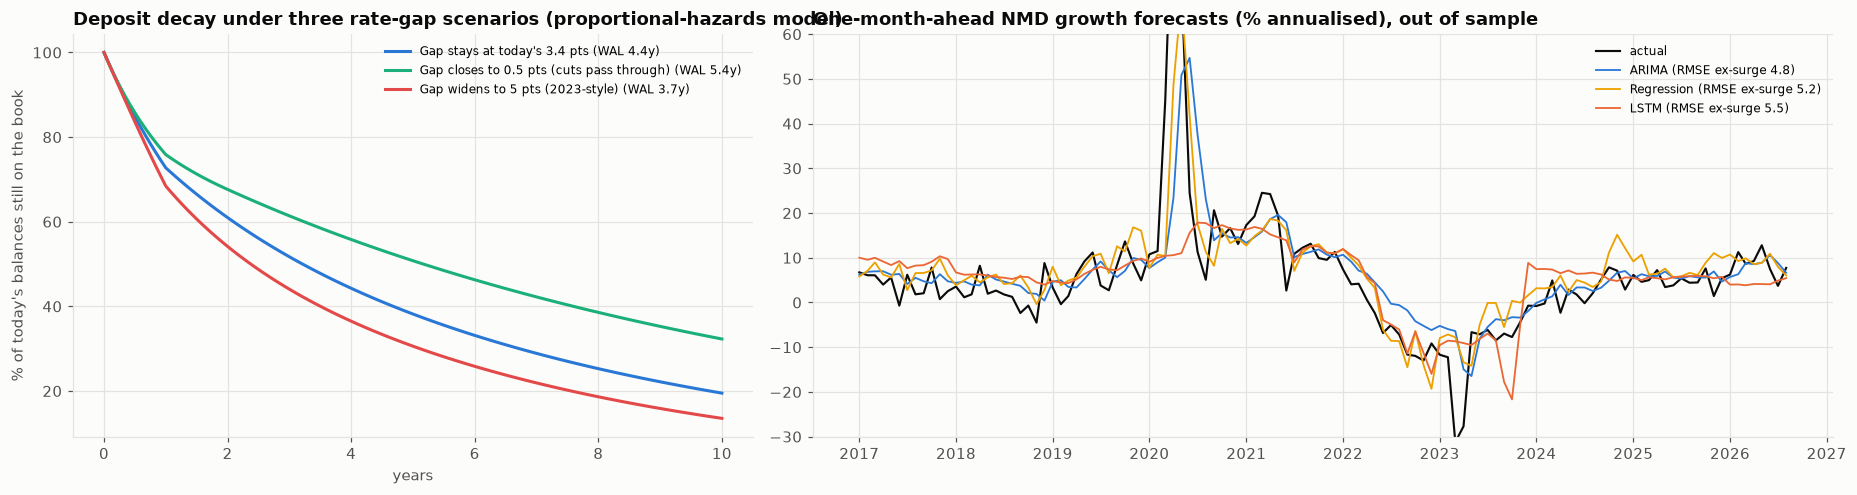

In [10]:
# --- Chart 2: decay curves and forecasts
fig, axes = plt.subplots(
    1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.5]}
)
ax = axes[0]
for (k, c), col in zip(decay.items(), [PALETTE[0], PALETTE[2], PALETTE[7]]):
    ax.plot(
        np.arange(len(c)) / 12,
        c * 100,
        color=col,
        lw=2,
        label=f"{k} (WAL {wal[k]:.1f}y)",
    )
ax.set_xlabel("years")
ax.set_ylabel("% of today's balances still on the book")
ax.set_title(
    "Deposit decay under three rate-gap scenarios (proportional-hazards model)"
)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(actual.index, actual, color=INK, lw=1.4, label="actual")
for k, col in zip(
    ["ARIMA", "Regression", "LSTM"], [PALETTE[0], PALETTE[3], PALETTE[1]]
):
    ax.plot(
        preds[k].index,
        preds[k],
        color=col,
        lw=1.2,
        label=(
            f"{k} (RMSE ex-surge {fc.loc[k, 'RMSE (ex 2020–21 surge)']:.1f})"
        ),
    )
ax.set_ylim(-30, 60)
ax.set_title(
    "One-month-ahead NMD growth forecasts (% annualised), out of sample"
)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_decay_and_forecasts")
plt.show()
cycle_beta.to_csv(OUT_DIR / "cycle_betas.csv")
ecm.to_csv(OUT_DIR / "ecm_betas.csv")
behav.to_csv(OUT_DIR / "behavioural_assumptions.csv")
fc.to_csv(OUT_DIR / "forecast_accuracy.csv")
cox.to_csv(OUT_DIR / "cox_recovery.csv")

## 8. Reading the results and limitations

U.S. non-maturity deposits ($15.5tn) and national deposit rates, 2009–2026:

**Deposit betas are low and asymmetric.** Over the 2022–2023 hiking cycle the national savings rate moved only 7 bp per 100 bp of fed funds, money-market accounts 10 bp and 12-month CDs 31 bp, about twice the betas of 2015–2019. In the error-correction model, increases in fed funds pass through faster than decreases for savings accounts (b⁺ 0.05 vs b⁻ 0.01, p < 0.001) and CDs (0.20 vs 0.10, p = 0.02).

The gap to the long-run beta closes slowly: half-lives of 32 months for savings, 17 for money-market accounts and 14 for CDs. National averages understate what large banks paid on rate-sensitive balances, so these are lower bounds.

**When the gap widens, deposits leave.** Each point of opportunity cost (fed funds minus the savings rate) cuts annualised NMD growth by about 1.3 points (R² 0.60), and the gap moves with money-fund inflows (correlation 0.53): the money goes to money-market funds. The GAM bends slightly (strong inflows at a zero gap, then a roughly linear response) but explains no more than the linear model (both AIC 1191). The linear rule is good enough for ALM.

**The survival model recovers the truth.** On 497,000 simulated account-months, the discrete-time proportional-hazards model recovers every coefficient within two standard errors (gap 0.16 vs 0.15, rate-sensitive 0.74 vs 0.70, interaction 0.14 vs 0.15, new-account effect 0.48 vs 0.47). It also recovers the baseline hazard, which a Cox model leaves unspecified and the projections need.

Lifelines' time-varying Cox fitter did not converge on this panel (heavy ties at every monthly tenure). The discrete-time equivalent is the practical choice for monthly account data.

**Rates drive the life of the book.** With the gap at today's 3.4 points, the weighted average life of a new deposit book (10-year cap) is **4.4 years**, with 38% still there after five years. If cuts pass through and the gap closes to 0.5 points, life rises to 5.4 years and the 5-year core to 51%.

A 2023-style gap of 5 points shortens it to 3.8 years and a 31% core. For IRRBB this is the difference between modelling NMD as a 4-year or a 5½-year liability, which changes the duration of equity materially.

**Deposit growth is hard to forecast a month ahead.** Out of sample (2017–2026), excluding the 2020–2021 stimulus surge, the random walk has the lowest RMSE (4.67), ahead of ARIMA (4.84), the regression (5.24) and the LSTM (5.48). In the 2022–2023 outflow period the random walk is again best (6.54 vs 7.6–8.2).

Including the surge, the regression is best overall (7.93), because the fed funds level helps in that period. The LSTM adds nothing over simple models on 40 years of monthly data.

**Limitations**

- National average rates (FDIC/FRED) are not any bank's rates. A bank would estimate betas on its own products and customer segments.
- The account panel is synthetic. Its coefficients are illustrative and chosen to give decay in the range banks report, and the value is the pipeline, not the numbers.
- Aggregate NMD mixes banks of all sizes; the 2023 outflows were concentrated in uninsured deposits at regional banks, which aggregate growth hides.

## References

### Finance and regulation

- Drechsler, I., Savov, A., & Schnabl, P. (2017). The deposits channel of monetary policy. *The Quarterly Journal of Economics, 132*(4), 1819–1876. https://doi.org/10.1093/qje/qjx019
- Drechsler, I., Savov, A., & Schnabl, P. (2021). Banking on deposits: Maturity transformation without interest rate risk. *The Journal of Finance, 76*(3), 1091–1143. https://doi.org/10.1111/jofi.13013
- Basel Committee on Banking Supervision. (2016). *Interest rate risk in the banking book* (BCBS 368). Bank for International Settlements. https://www.bis.org/bcbs/publ/d368.htm
- Hutchison, D. E., & Pennacchi, G. G. (1996). Measuring rents and interest rate risk in imperfect financial markets: The case of retail bank deposits. *Journal of Financial and Quantitative Analysis, 31*(3), 399–417. https://doi.org/10.2307/2331398
- Neumark, D., & Sharpe, S. A. (1992). Market structure and the nature of price rigidity: Evidence from the market for consumer deposits. *The Quarterly Journal of Economics, 107*(2), 657–680. https://doi.org/10.2307/2118485

### Machine learning and deep learning

- Hastie, T., & Tibshirani, R. (1986). Generalized additive models. *Statistical Science, 1*(3), 297–310. https://doi.org/10.1214/ss/1177013604
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society: Series B, 34*(2), 187–202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x